# OGBench with a RoboJEPA baseline

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/envs/ogbench.ipynb)

[OGBench](https://github.com/seohongpark/ogbench) is an offline goal-conditioned benchmark: a world model trains on a fixed dataset of play data, then reaches goals it has never been shown. Here the task is `visual-cube-single-play-v0`, a UR5e arm that must move a cube to a goal pose seen only as a 64 × 64 goal image, across OGBench's five evaluation tasks.

The baseline is [RoboJEPA](../../docs/models/jepa/robojepa.md) in its simplest form: one camera, no proprioception, and raw 8 × 8 pixel patches in place of the frozen V-JEPA 2.1 encoder. It trains on chunks of five actions, as DINO-WM does on OGBench, and plans with CEM toward the embedding of the goal image.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples,ogbench]"

In [1]:
import time

import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader

from torch_world import plots
from torch_world.datasets import TrajectoryDataset, load_ogbench
from torch_world.envs import OGBench
from torch_world.models import RoboJEPA
from torch_world.planning import CEM, RecedingHorizon

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
amp = torch.autocast(device, dtype=torch.bfloat16)  # matmuls in bf16; losses and planner statistics stay float32
NAME = "visual-cube-single-play-v0"
FRAMESKIP, WINDOW, GRID = 5, 4, (8, 8)

## Data

`load_ogbench` downloads the dataset once into `~/.ogbench/data` and stacks it into episodes `(N, T, ...)`; images stay uint8 to save memory. Each training window holds four frames five steps apart, and each of its steps the five actions that follow the frame.

{'observations': (1000, 1001, 3, 64, 64), 'actions': (1000, 1001, 5)} {'observations': (100, 1001, 3, 64, 64), 'actions': (100, 1001, 5)}


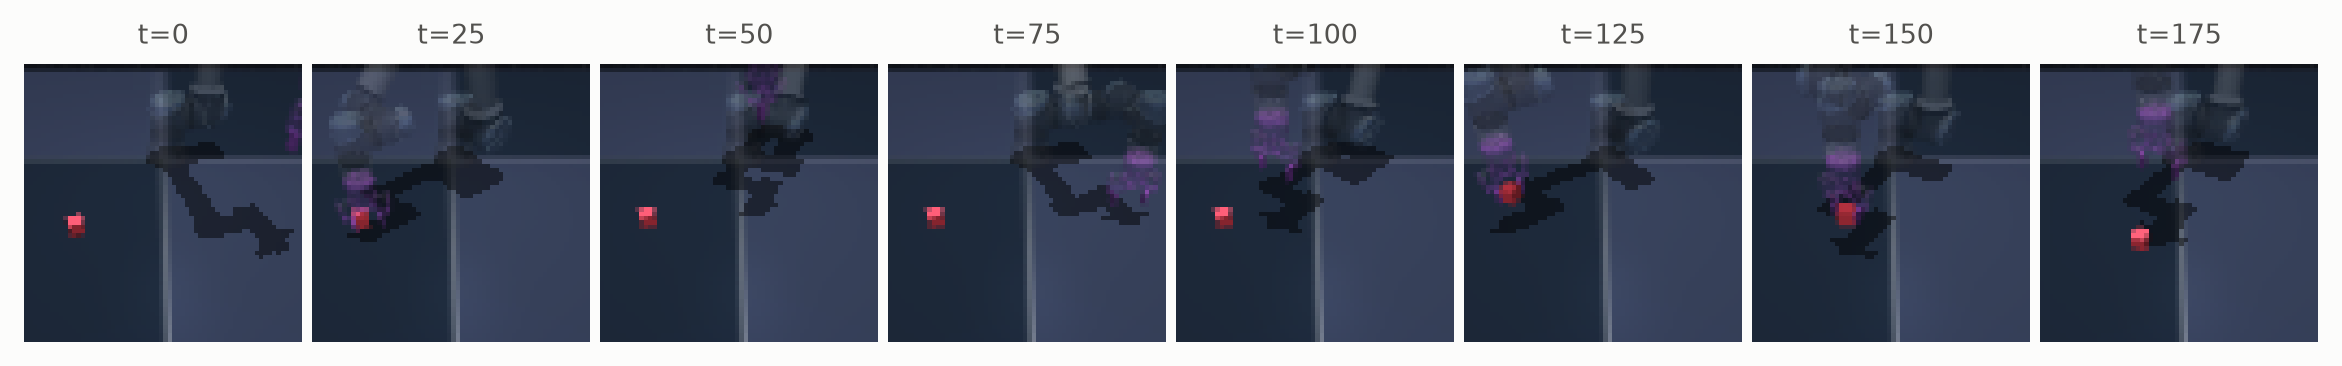

In [2]:
train, val = load_ogbench(NAME), load_ogbench(NAME, split="val")
print({k: tuple(v.shape) for k, v in train.items()}, {k: tuple(v.shape) for k, v in val.items()})
loader = DataLoader(
    TrajectoryDataset(train, window=WINDOW, frameskip=FRAMESKIP), batch_size=64, shuffle=True, drop_last=True, num_workers=4
)
episode = train["observations"][0, : 8 * 25 : 25]
plots.images(episode, [f"t={25 * i}" for i in range(8)])

## Model

The encoder cuts a frame into 64 patches of 8 × 8 pixels, so a timestep is 64 patch tokens and one action token.

In [3]:
class Patchify(nn.Module):
    def forward(self, x):
        return F.pixel_unshuffle(x, 8).flatten(2).transpose(1, 2)


def frames(observations):
    """Images ``(B, T, 3, H, W)``, uint8 or in [0, 1], as one camera view ``(B, T, 1, 3, H, W)`` in [0, 1]."""
    x = observations.float() / 255 if observations.dtype == torch.uint8 else observations
    return x.unsqueeze(2)


model = RoboJEPA(
    embed_dim=192, action_dim=5 * FRAMESKIP, num_views=1, predictor_dim=256, depth=6, num_heads=4,
    window=WINDOW, rollout_steps=2, encoder=Patchify(),
).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

4.84M parameters


## Train

15000 updates in 49.1 min


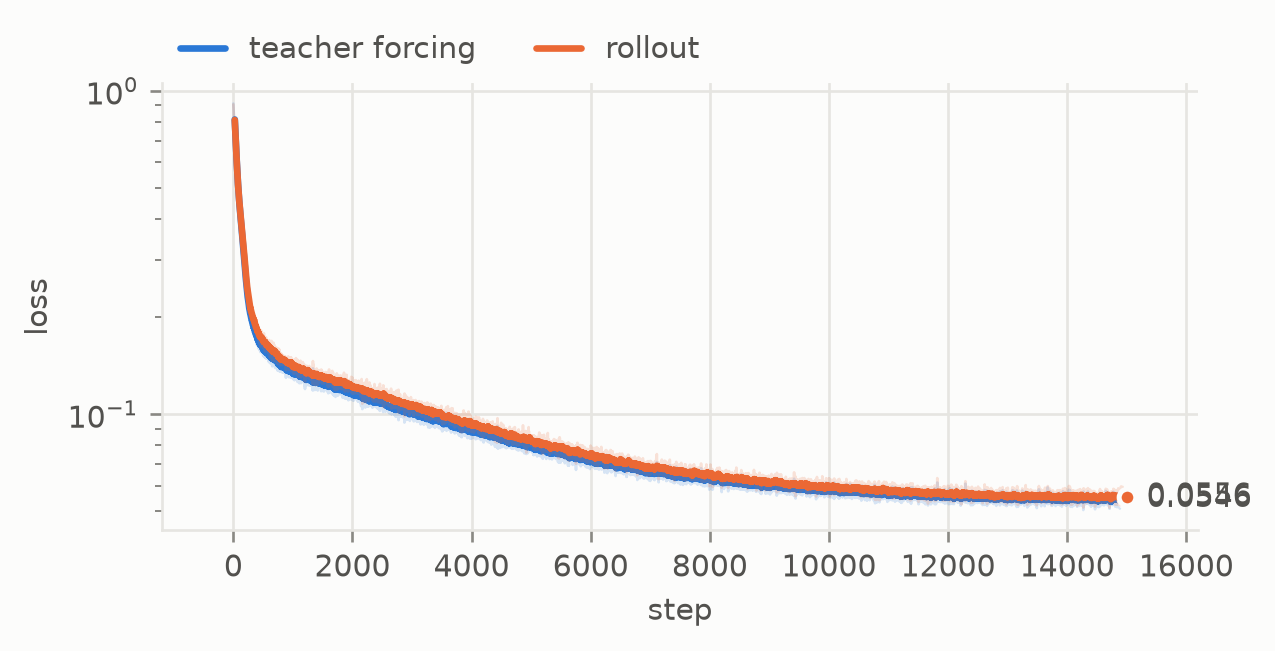

In [4]:
STEPS = 15000
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.04)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-4, total_steps=STEPS, pct_start=0.05)
log, step, tic = {"teacher forcing": [], "rollout": []}, 0, time.perf_counter()
model.train()
while step < STEPS:
    for batch in loader:
        z = model.encode(frames(batch["observations"].to(device, non_blocking=True)), GRID)
        with amp:
            out = model(z, batch["actions"].to(device))
        opt.zero_grad(set_to_none=True)
        out["loss"].backward()
        opt.step()
        sched.step()
        log["teacher forcing"].append(out["tf_loss"].item())
        log["rollout"].append(out["rollout_loss"].item())
        step += 1
        if step == STEPS:
            break
model.eval()
print(f"{STEPS} updates in {(time.perf_counter() - tic) / 60:.1f} min")
plots.curves(log)

## Held-out prediction

On the validation episodes, the model predicts the next latent of every window. Copying the last latent forward is the persistence baseline: a model that learned nothing about actions does no better than it.

In [5]:
val_windows = TrajectoryDataset(val, window=WINDOW, frameskip=FRAMESKIP)
idx = torch.randperm(len(val_windows), generator=torch.Generator().manual_seed(0))[:1024]
errors = {"RoboJEPA": [], "persistence": []}
with torch.no_grad():
    for chunk in idx.split(128):
        batch = [val_windows[i] for i in chunk.tolist()]
        obs = torch.stack([b["observations"] for b in batch]).to(device)
        actions = torch.stack([b["actions"] for b in batch]).to(device)
        z = model.encode(frames(obs), GRID)
        with amp:
            pred = model.predict(z[:, :-1], actions[:, :-1]).float()
        errors["RoboJEPA"].append((pred[:, -1] - z[:, -1]).abs().mean().item())
        errors["persistence"].append((z[:, -2] - z[:, -1]).abs().mean().item())
for name, e in errors.items():
    print(f"{name:12s} next-latent L1 {sum(e) / len(e):.4f}")

RoboJEPA     next-latent L1 0.0545
persistence  next-latent L1 0.1404


## Plan toward the goal image

CEM plans five chunks of five actions toward the encoded goal; the arm runs the first two chunks, then the planner looks again. Each of OGBench's five evaluation tasks runs eight seeded episodes, against random actions. Episodes end at success or after OGBench's 200 steps.

/clusterhome/kleyton/pytorch-world-benchmarks-20261018/.venv/lib/python3.12/site-packages/gymnasium/spaces/box.py:297: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
/clusterhome/kleyton/pytorch-world-benchmarks-20261018/.venv/lib/python3.12/site-packages/gymnasium/spaces/box.py:364: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


random          {'task 1': '0.00', 'task 2': '0.00', 'task 3': '0.00', 'task 4': '0.00', 'task 5': '0.00'} mean 0.00


RoboJEPA + CEM  {'task 1': '0.00', 'task 2': '0.00', 'task 3': '0.00', 'task 4': '0.00', 'task 5': '0.00'} mean 0.00
evaluation in 20.6 min


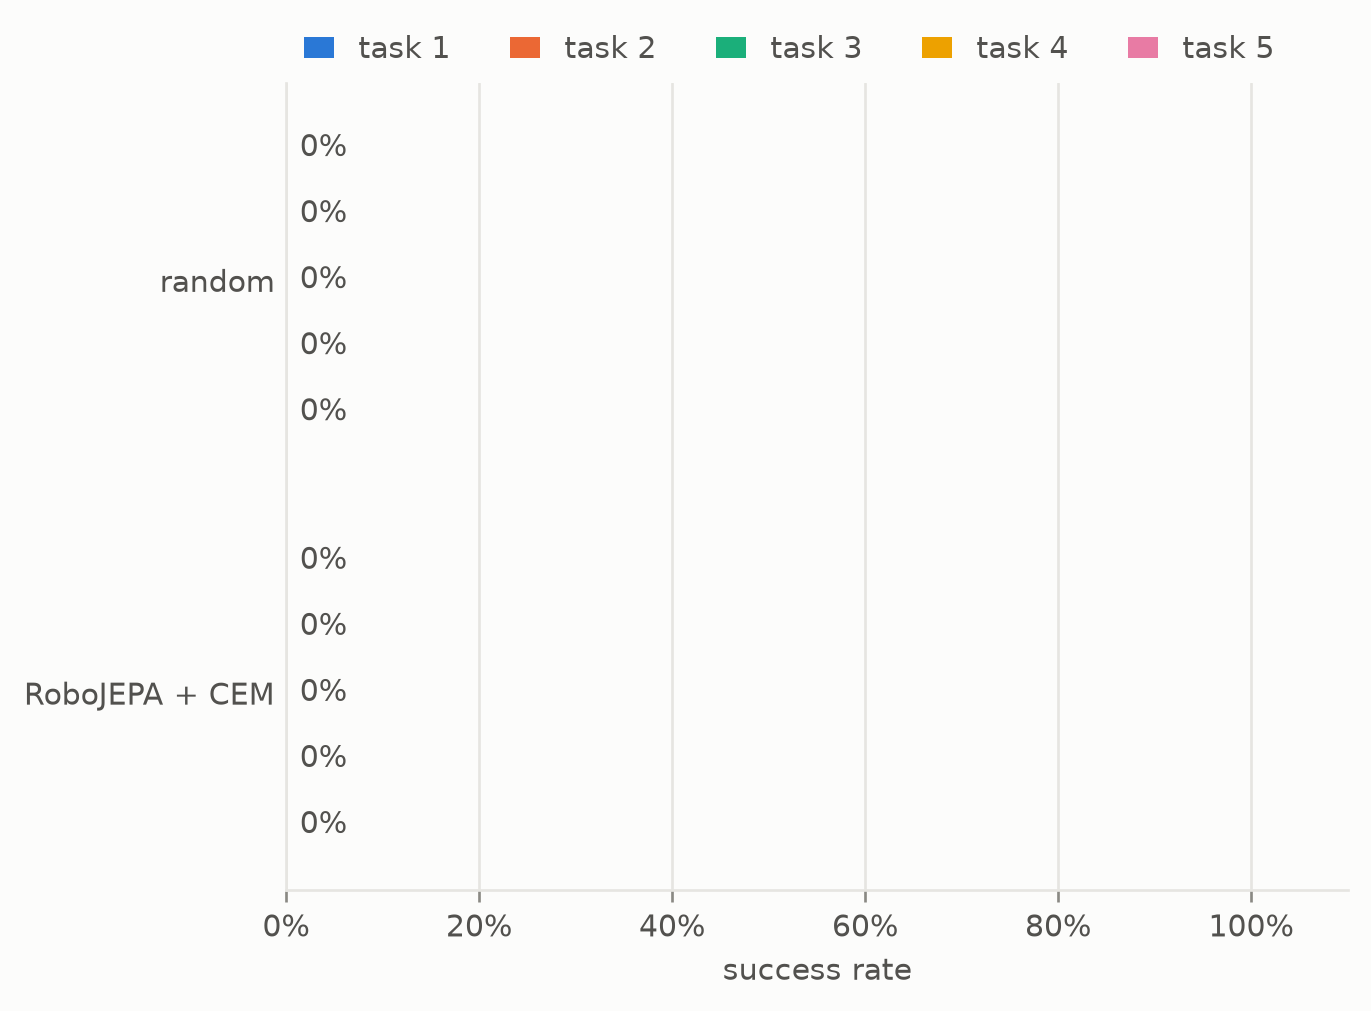

In [6]:
planner = CEM(horizon=5, action_dim=5 * FRAMESKIP, num_samples=128, num_elites=16, iterations=5, bounds=(-1, 1), objective="path")
EPISODES, results, videos = 8, {}, {}


def evaluate(task_id, kind):
    world = OGBench(NAME, task_id=task_id, batch_size=EPISODES, render_size=128)
    world.reset(seed=1000 + task_id)
    goal = model.encode(frames(world.goal[:, None].to(device)), GRID)[:, 0]

    def plan(obs):
        z = model.encode(frames(obs[:, None].to(device)), GRID)
        with amp:
            return planner(model, z, goal).float().cpu()

    policy = RecedingHorizon(plan, action_dim=5, execute=2) if kind == "RoboJEPA + CEM" else (lambda obs: torch.rand(EPISODES, 5) * 2 - 1)
    success, video = torch.zeros(EPISODES, dtype=torch.bool), [world.render_frame()]
    obs = world.render()
    while not world.transition.done.all():
        obs = world.step(policy(obs))
        success |= world.transition.success
        video.append(world.render_frame())
    goals = world.render_goal_frame()
    world.close()
    return success, torch.stack(video, 1), goals


tic = time.perf_counter()
for kind in ("random", "RoboJEPA + CEM"):
    results[kind] = {}
    for task_id in range(1, 6):
        success, video, goals = evaluate(task_id, kind)
        results[kind][f"task {task_id}"] = success.float().mean().item()
        videos[kind, task_id] = video, goals, success
    print(f"{kind:15s}", {k: f"{v:.2f}" for k, v in results[kind].items()}, f"mean {sum(results[kind].values()) / 5:.2f}")
print(f"evaluation in {(time.perf_counter() - tic) / 60:.1f} min")
plots.bars(results, xlabel="success rate")

One planned episode per task, beside OGBench's rendering of its goal.


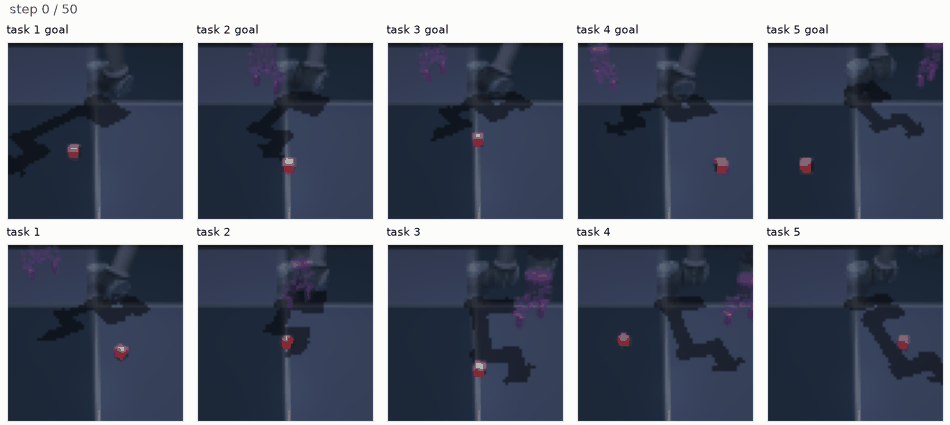

In [7]:
video = torch.stack([videos["RoboJEPA + CEM", t][0][0] for t in range(1, 6)])
goals = torch.stack([videos["RoboJEPA + CEM", t][1][0] for t in range(1, 6)])
tiles = torch.cat([goals[:, None].expand(-1, video.size(1), -1, -1, -1), video])
titles = [f"task {t} goal" for t in range(1, 6)] + [f"task {t}" for t in range(1, 6)]
plots.episodes(tiles[:, ::4], titles=titles, ncols=5, fps=6)

Raw pixel patches and 15k updates make a deliberately small baseline. The usual next steps are the frozen V-JEPA 2.1 encoder RoboJEPA was designed for, the arm's proprioception (`load_ogbench(..., info=True)` adds `qpos` and `qvel`), and longer training. Any other OGBench task works the same way: `OGBench(name)` and `load_ogbench(name)` take OGBench's dataset names.